# Which email should we send? A randomized test of 64,000 customers

**Reader:** Head of e-commerce marketing. **Decision:** send the Men's email, the Women's email, or neither, to the customer base.
The plan, metrics and decision rule were written in [research_plan.md](../research_plan.md) before outcomes were analyzed.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ab
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"
df = ab.load()
ctrl = df[df.segment == ab.CONTROL]
MARGIN, COST = 0.40, 0.05   # assumptions from the plan, editable in the app

## 1. Did the randomization work?

In [2]:
counts, chi2, p = ab.sample_ratio_check(df)
print(counts.to_string()); print(f"\nSample-ratio check vs equal split: chi2={chi2:.2f}, p={p:.3f}")
cov = ["recency", "history", "mens", "womens", "newbie"]
bal = pd.DataFrame({a: ab.smd(df, cov, a) for a in ab.ARMS}).round(3)
print("\nStandardized mean difference vs control (|SMD| < 0.1 is balanced):"); bal

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306

Sample-ratio check vs equal split: chi2=0.20, p=0.904

Standardized mean difference vs control (|SMD| < 0.1 is balanced):


,Mens E-Mail,Womens E-Mail
recency,0.007,0.005
history,0.008,0.007
mens,-0.005,-0.009
womens,0.008,0.005
newbie,-0.001,0.003


Arm sizes are consistent with an equal three-way split (p = 0.90) and every covariate is balanced (|SMD| < 0.01). We can read differences in outcomes as effects of the email.
**Data note:** the file has no customer ID. 6,562 exact-duplicate rows are customers with identical attributes, not a data-entry error, so none were removed.

## 2. Effects on visits, conversions and spend

In [3]:
rows = []
for m in ["visit", "conversion", "spend"]:
    for a in ab.ARMS:
        t = df[df.segment == a]
        r = ab.diff_in_props(t[m], ctrl[m]) if m != "spend" else ab.diff_in_means(t[m], ctrl[m])
        rows.append(dict(metric=m, arm=a, treated=t[m].mean(), control=ctrl[m].mean(),
                         diff=r["diff"], ci_lo=r["lo"], ci_hi=r["hi"], p=r["p"]))
res = pd.DataFrame(rows)
res["p_holm"] = res.groupby("metric").p.transform(lambda s: ab.holm(s.values))
res["rel_lift_%"] = 100 * res["diff"] / res["control"]
res.round(4)

,metric,arm,treated,control,diff,ci_lo,ci_hi,p,p_holm,rel_lift_%
0,visit,Mens E-Mail,0.1828,0.1062,0.0766,0.0700,0.0832,0.0000,0.0000,72.1405
1,visit,Womens E-Mail,0.1514,0.1062,0.0452,0.0389,0.0516,0.0000,0.0000,42.6055
2,conversion,Mens E-Mail,0.0125,0.0057,0.0068,0.0050,0.0086,0.0000,0.0000,118.8422
3,conversion,Womens E-Mail,0.0088,0.0057,0.0031,0.0015,0.0047,0.0002,0.0002,54.3313
4,spend,Mens E-Mail,1.4226,0.6528,0.7698,0.4923,1.0520,0.0000,0.0000,117.9289
5,spend,Womens E-Mail,1.0772,0.6528,0.4244,0.1776,0.6757,0.0011,0.0011,65.0152


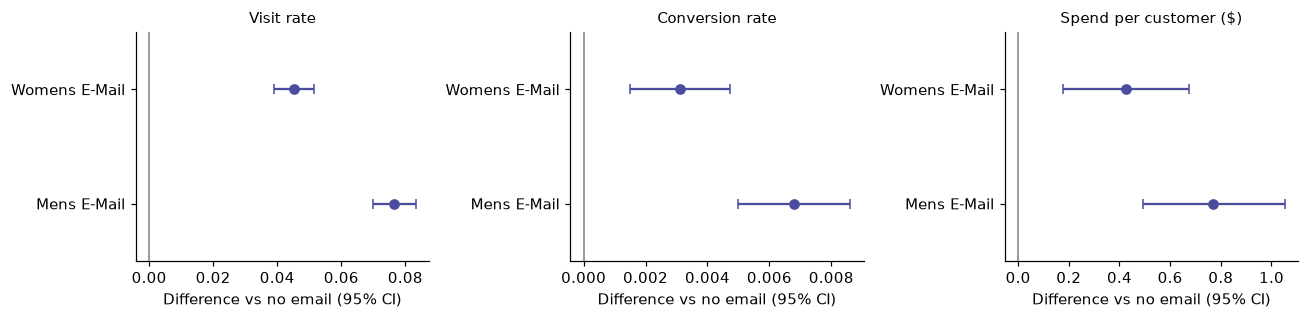

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, m, lab in zip(axes, ["visit", "conversion", "spend"], ["Visit rate", "Conversion rate", "Spend per customer ($)"]):
    d = res[res.metric == m].reset_index(drop=True)
    ax.errorbar(d["diff"], range(len(d)), xerr=[d["diff"] - d.ci_lo, d.ci_hi - d["diff"]], fmt="o", color="#4c4c9d", capsize=3)
    ax.axvline(0, color="grey", lw=1); ax.set_yticks(range(len(d)), d.arm); ax.set_title(lab, fontsize=10)
    ax.set_xlabel("Difference vs no email (95% CI)"); ax.set_ylim(-0.5, 1.5)
plt.tight_layout(); plt.savefig(FIG + "effects.png"); plt.show()

Both emails raise visits, conversions and spend, and all six comparisons stay significant after Holm correction. The Men's email lifts visit rate by 7.7 points (from 10.6% to 18.3%), the Women's by 4.5 points.
Spend is mostly zeros with a long tail (std $11.6 to $17.8 against a mean under $1.50), which is why the spend interval is a bootstrap and not a textbook formula. The Welch test agrees with it.

## 3. Sharpening the estimate with past spend (CUPED)
Past spend (`history`) is measured before assignment, so it can be used to remove noise without biasing the estimate.

In [5]:
cup = pd.DataFrame({a: {k: v for k, v in ab.cuped(df, "spend", "history", a).items() if k != "boots"} for a in ab.ARMS}).T
raw = res[res.metric == "spend"].set_index("arm")
pd.DataFrame({"raw_diff": raw["diff"], "raw_ci_width": raw.ci_hi - raw.ci_lo,
              "cuped_diff": cup["diff"], "cuped_ci_width": cup.hi - cup.lo,
              "variance_removed_%": 100 * cup.var_reduction}).round(4)

,raw_diff,raw_ci_width,cuped_diff,cuped_ci_width,variance_removed_%
Mens E-Mail,0.7698,0.5597,0.7674,0.5671,0.0438
Womens E-Mail,0.4244,0.4981,0.4227,0.5006,0.0381


**Prediction missed.** I expected past spend to tighten the intervals noticeably. It removes 0.04% of the variance, so the adjusted and raw results are indistinguishable.
In hindsight, `history` is a poor predictor of a two-week purchase that happens for only about 1% of customers. CUPED helps when the pre-period metric predicts the outcome, and here it does not. I report it for completeness and do not use it for the decision.

## 4. Do some customers respond differently?
Subgroups were fixed in the plan: new vs. existing, channel, past-spend segment. The test is an interaction F-test per subgroup, corrected across all six tests (2 emails x 3 subgroups).

In [6]:
het = []
for a in ab.ARMS:
    for s in ["newbie", "channel", "history_segment"]:
        f, p = ab.interaction_test(df, "spend", s, a)
        het.append(dict(arm=a, subgroup=s, F=f, p=p))
het = pd.DataFrame(het); het["p_holm"] = ab.holm(het.p.values)
het.round(4)

,arm,subgroup,F,p,p_holm
0,Mens E-Mail,newbie,1.7299,0.1884,0.5653
1,Mens E-Mail,channel,1.0616,0.3459,0.6918
2,Mens E-Mail,history_segment,0.9957,0.4261,0.6918
3,Womens E-Mail,newbie,5.6222,0.0177,0.0887
4,Womens E-Mail,channel,2.3971,0.0910,0.3640
5,Womens E-Mail,history_segment,2.8906,0.0081,0.0487


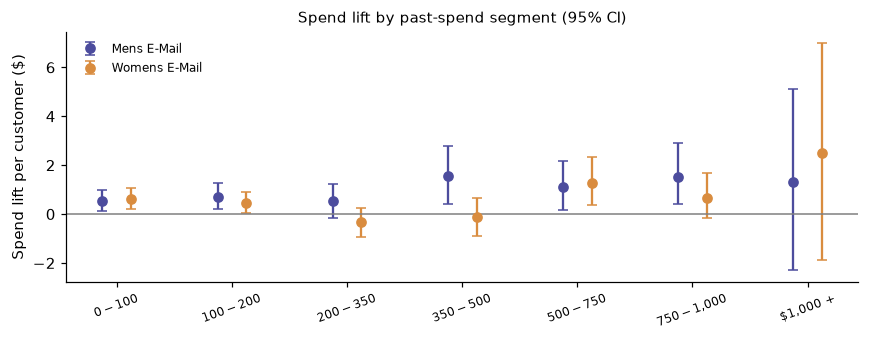

,history_segment,arm,n,diff,lo,hi
0,1) $0 - $100,Mens E-Mail,7724,0.538,0.108,0.982
1,1) $0 - $100,Womens E-Mail,7634,0.626,0.195,1.056
2,2) $100 - $200,Mens E-Mail,4691,0.704,0.214,1.259
3,2) $100 - $200,Womens E-Mail,4727,0.458,0.043,0.884
4,3) $200 - $350,Mens E-Mail,4090,0.537,-0.161,1.231
5,3) $200 - $350,Womens E-Mail,4155,-0.323,-0.934,0.229
6,4) $350 - $500,Mens E-Mail,2097,1.569,0.423,2.787
7,4) $350 - $500,Womens E-Mail,2188,-0.101,-0.901,0.663
8,5) $500 - $750,Mens E-Mail,1597,1.103,0.168,2.162
9,5) $500 - $750,Womens E-Mail,1662,1.286,0.368,2.337


In [7]:
sub = []
for seg, g in df.groupby("history_segment"):
    c = g[g.segment == ab.CONTROL].spend
    for a in ab.ARMS:
        t = g[g.segment == a].spend
        r = ab.diff_in_means(t, c, n_boot=2000)
        sub.append(dict(history_segment=seg, arm=a, n=len(t), diff=r["diff"], lo=r["lo"], hi=r["hi"]))
sub = pd.DataFrame(sub)
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (a, col) in enumerate(zip(ab.ARMS, ["#4c4c9d", "#d98c3f"])):
    d = sub[sub.arm == a]; x = np.arange(len(d)) + (i - 0.5) * 0.25
    ax.errorbar(x, d["diff"], yerr=[d["diff"] - d.lo, d.hi - d["diff"]], fmt="o", color=col, capsize=3, label=a)
ax.set_xticks(range(len(d)), [s[3:] for s in d.history_segment], rotation=20, fontsize=8)
ax.axhline(0, color="grey", lw=1); ax.set_ylabel("Spend lift per customer ($)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Spend lift by past-spend segment (95% CI)", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "heterogeneity.png"); plt.show()
sub.round(3)

Only one test reaches the threshold: the Women's email effect varies by past-spend segment (corrected p = 0.049, borderline). The other five do not. Because it is one of six tests and the corrected p-value sits right on the line, I treat it as a lead to confirm in a follow-up experiment, not as grounds for targeting by segment.
The Women's pattern is not monotone: point estimates are negative at $200-$350 and $350-$500 and positive on both sides, with intervals that include zero. That looks more like noise than a targeting rule.
**Prediction partly missed:** I expected no interaction to survive.

## 5. From statistically real to worth acting on
The decision rule from the plan: send only if the **lower bound of the adjusted 95% interval for incremental profit per customer is above zero**. Two comparisons, so the interval uses the 1.25th/98.75th percentiles (Bonferroni, slightly conservative).
`profit = margin x spend lift - cost per email`, with margin = 40% and cost = $0.05 (assumptions, not data).

In [8]:
out = []
for a in ab.ARMS:
    t = df[df.segment == a]
    r = ab.diff_in_means(t.spend, ctrl.spend, n_boot=10000, seed=1)
    lo, hi = np.percentile(r["boots"], [1.25, 98.75])
    out.append(dict(arm=a, spend_lift=r["diff"], profit_per_customer=ab.incremental_profit(r["diff"], MARGIN, COST),
                    profit_lo=ab.incremental_profit(lo, MARGIN, COST), profit_hi=ab.incremental_profit(hi, MARGIN, COST)))
prof = pd.DataFrame(out).set_index("arm")
prof["send?"] = np.where(prof.profit_lo > 0, "yes", "no")
prof["profit_per_100k_sent"] = 100_000 * prof.profit_per_customer
prof.round(3)

,spend_lift,profit_per_customer,profit_lo,profit_hi,send?,profit_per_100k_sent
arm,,,,,,
Mens E-Mail,0.770,0.258,0.132,0.390,yes,25793.086
Womens E-Mail,0.424,0.120,0.002,0.239,yes,11976.489


In [9]:
sens = {}
for a in ab.ARMS:
    t = df[df.segment == a]
    dd = ab.diff_in_means(t.spend, ctrl.spend, n_boot=10000, seed=1)
    lo_spend = np.percentile(dd["boots"], 1.25)
    margins = np.array([0.2, 0.3, 0.4, 0.5, 0.6]); costs = np.array([0.02, 0.05, 0.10, 0.15, 0.20])
    sens[a] = pd.DataFrame([[ab.incremental_profit(lo_spend, m, c) for m in margins] for c in costs],
                           index=[f"cost ${c:.2f}" for c in costs], columns=[f"margin {int(m*100)}%" for m in margins])
    print(a, ": lower bound of incremental profit per customer (positive = passes the rule)")
    print(sens[a].round(3).to_string(), "\n")

Mens E-Mail : lower bound of incremental profit per customer (positive = passes the rule)
            margin 20%  margin 30%  margin 40%  margin 50%  margin 60%
cost $0.02       0.071       0.117       0.162       0.208       0.253
cost $0.05       0.041       0.087       0.132       0.178       0.223
cost $0.10      -0.009       0.037       0.082       0.128       0.173
cost $0.15      -0.059      -0.013       0.032       0.078       0.123
cost $0.20      -0.109      -0.063      -0.018       0.028       0.073 



Womens E-Mail : lower bound of incremental profit per customer (positive = passes the rule)
            margin 20%  margin 30%  margin 40%  margin 50%  margin 60%
cost $0.02       0.006       0.019       0.032       0.045       0.059
cost $0.05      -0.024      -0.011       0.002       0.015       0.029
cost $0.10      -0.074      -0.061      -0.048      -0.035      -0.021
cost $0.15      -0.124      -0.111      -0.098      -0.085      -0.071
cost $0.20      -0.174      -0.161      -0.148      -0.135      -0.121 



Both emails clear the rule at these assumptions, the Men's email by a wide margin: about $0.26 per customer after costs, roughly twice the Women's (about $0.12).
The Women's email is the closer call: its lower bound at the base case is $0.002, effectively zero. Reading the grids, the Women's email fails the rule at 30% margin with a $0.05 send cost, or at any margin once the cost reaches $0.10. The Men's email fails only when cost is high relative to margin: $0.10 at a 20% margin, $0.15 at 30%, or $0.20 at 40%. Negative cells mean "do not send".
**The recommendation depends on margin and cost, so the marketing team should replace my assumptions with their own.** The Streamlit app does this.

## 6. How early looks can fool you: a peeking simulation

No true effect. Check daily for 14 days and stop at first p<0.05: 20.9% false wins
Same experiment, test once at day 14:                           4.7% false wins


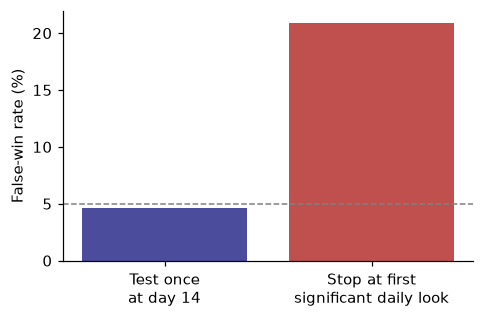

In [10]:
fp_peek, fp_once = ab.peeking_simulation(n_per_day=1000, days=14, base_rate=0.10, n_sims=5000)
print(f"No true effect. Check daily for 14 days and stop at first p<0.05: {fp_peek:.1%} false wins")
print(f"Same experiment, test once at day 14:                           {fp_once:.1%} false wins")
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["Test once\nat day 14", "Stop at first\nsignificant daily look"], [fp_once * 100, fp_peek * 100], color=["#4c4c9d", "#c0504d"])
ax.axhline(5, color="grey", ls="--", lw=1); ax.set_ylabel("False-win rate (%)"); plt.tight_layout()
plt.savefig(FIG + "peeking.png"); plt.show()

An experiment with **no effect** declares a winner about 21% of the time if someone checks daily and stops at the first p < 0.05, four times the 5% the test promises. This is why the plan fixed the sample and the decision rule before launch.

## Findings
1. **Randomization is sound** (sample-ratio p = 0.90; all covariates balanced), so the differences are causal effects of the emails.
2. **Both emails work.** Men's: +7.7 pts visits, +0.7 pts conversion, +$0.77 spend per customer. Women's: +4.5 pts, +0.3 pts, +$0.42. All significant after correction.
3. **Statistically real is not the same as worth sending.** After a stated margin and send cost, the Men's email earns about $0.26 per customer (interval clearly above zero). The Women's earns about $0.12 and its lower bound is barely above zero, so it is sensitive to the margin and cost assumptions.
4. **Past-spend adjustment did not help** (0.04% variance removed). One Women's-email subgroup interaction is borderline after correction and is a lead, not a finding.
5. **Peeking inflates false wins from 5% to 21%** in a no-effect experiment.

## Limits
Two-week window (no fatigue, unsubscribes or later cannibalization); revenue, not margin; assumed cost and margin; one 2008 campaign; intent-to-treat (we do not see who opened the email).